In [1]:
#!/usr/bin/env python3
# coding: utf-8

"""
File: optimization_manager.py
Author: Matthew Ogden
Email: ogdenm12@gmail.com
Github: mbogden
Created: 2024-Nov-11

References:  Sections of this code were enhanced with the assistance of ChatGPT made by OpenAI.
"""

# ================================ STANDARD IMPORTS ================================ #
import logging
import os
import sys
import time
import numpy as np
import pandas as pd

# partial imports
from mpi4py import MPI

# ================================ PROJECT MODULES ================================ #
# Add main project directory to import project modules
try:
    SCRIPT_DIRECTORY = os.path.dirname(os.path.realpath(__file__))
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    sys.path.append(PROJECT_DIRECTORY)

except:
    # Consider we are running from the script directory
    SCRIPT_DIRECTORY = os.getcwd()
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    
    # Also consider you might be in galStuff directory
    work_dir = os.getcwd()
    if 'galStuff' == work_dir.split('/')[-1]:
        PROJECT_DIRECTORY =  work_dir + '/galaxyJSPAM'
        sys.path.append(PROJECT_DIRECTORY) 

# import project modules
import utilities.general_utility as gu
import utilities.parallel_queue_manager as qm
import Optimization_Methods.optimization_support as opt_spt

# ================================ GLOBAL VARIABLES ================================ #
buildEnv = False

# Global logger from main program
SCRIPTS_ARGUMENTS, logger = gu.initialize_environment(module_name='optimizer') # Testing using multiple loggers for tiered log levels.
# SCRIPTS_ARGUMENTS, logger = gu.initialize_environment(module_name='') 

# Generate random instance
rng = np.random.default_rng()
logger.info("Imported Loaded")

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-t5tc8dd9 because the default path (/home/jovyan/.cache/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
[2025-03-17 14:59:19,447 - INFO - 1176312661.optimizer.<module>]: Imported Loaded


In [2]:
# Development Cell:  This should only be present in the Jupyter Notebook version of this script for development purposes.
buildEnv = True
logger.info("Running in Development Build Mode")

from importlib import reload

# Warn user if NOT in jupyter notebook, require a yes/no response to continue or not
if "ipykernel" not in sys.modules:
    msg = "Development Environment Detected.  This will run several tests and attempt to creat plots.  Do you want to continue?..."

    # Get user input
    while True:
        response = input(f"{msg} (y/n): ").lower()
        if response in ['y', 'yes']:
            break
        elif response in ['n', 'no']:
            print("Exiting...")
            sys.exit()
        else:
            print("Invalid input. Please enter 'y' or 'n'.")



[2025-03-17 14:59:19,458 - INFO - 2660316776.optimizer.<module>]: Running in Development Build Mode


# Genetic Algorithm


In [ ]:
import pygad

class PYGAD_Manager:
    """
    Class to manage the PYGAD optimizer.
    """
    """Initialize the PYGAD optimizer with the function to evaluate.
    ga_config = {
        "num_generations": 100,  # Number of generations to run the GA.
        "num_parents_mating": 4,  # Number of solutions to be selected as parents.
        "sol_per_pop": 10,  # Number of solutions per population.

        "num_genes": 5  # Number of genes in each solution.
        "gene_space": None,  # Restrict gene values to specific ranges or discrete sets.
        "gene_type": float,  # Data type of the genes. Can be float, int, or a list of types.

        "fitness_func": None,  # User-defined fitness function to evaluate solutions.
        "initial_population": None,  # User-defined initial population. If None, GA initializes randomly.
        "stop_criteria": None,  # Criteria to stop the evolution early (e.g., "reach_40", "saturate_7").
        "random_seed": None,  # Set random seed for reproducibility.
        "logger": None  # Logger for capturing outputs.
        "keep_elitism": 1,  # Number of top solutions to keep in the next generation without mutation.  (overwrites keep_parent below)
        "keep_parents": 0,  # Number of parents to keep with mutations in next generation.
        "parent_selection_type": "sus",  # Parent selection strategy 
            # Balanced:['rank', 'sus', 'tournament']
            # Fast/Risky:['sss', 'rws']
            # Exploration: ['random']

        "crossover_type": "single_point",  # Crossover strategy.
            # Lumps genes together: ['single_point', 'two_points'] 
            # High diversity/random mixing: ['uniform', 'scattered']
            # Note, lumping degenerate genes can help.  Consider custom one later
        
        "mutation_probability": [0.1, 0.5]  # [Low, High] Probability for best/worst solutions in adaptive mutation.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
        "mutation_type": "adaptive",  # Mutation strategy.
            # Simple/Explorative: ['random', 'scramble']
            # Order-focused: ['swap', 'inversion']
            # Smart/Adaptive: ['adaptive']
    }

    pygad_callbacks = {
        "on_start": {
            "description": "Called once before the genetic algorithm starts.",
            "parameters": ["ga_instance"]  # If method: ["ga_instance", "self"]
        },
        "on_fitness": {
            "description": "Called after calculating the fitness values of all solutions.",
            "parameters": ["fitness_values", "ga_instance"]  # If method: ["fitness_values", "ga_instance", "self"]
        },
        "on_parents": {
            "description": "Called after selecting parents for mating.",
            "parameters": ["parents", "ga_instance"]  # If method: ["parents", "ga_instance", "self"]
        },
        "on_crossover": {
            "description": "Called each time the crossover operation is applied.",
            "parameters": ["ga_instance", "offspring"]
        },
        "on_mutation": {
            "description": "Called each time the mutation operation is applied.",
            "parameters": ["ga_instance", "mutated_offspring"]
        },
        "on_generation": {
            "description": "Called after each generation. Returning 'stop' halts the run.",
            "parameters": ["ga_instance"]
        },
        "on_stop": {
            "description": "Called once before the algorithm stops or after the last generation.",
            "parameters": ["ga_instance", "last_gen_fitness"]
        }
    }

    """

    def __init__( self, 
                 ga_config: dict, 
                 input_space: list = None,
                 space_manager: opt_spt.Space_Manager = None, 
                 black_box_function: callable = None,
                 execution_manager: opt_spt.Execution_Manager = None,
                 log_level = logging.INFO
                 ):
        
        # Set logger
        self.logger = gu.configure_logger( logger_name='pygad_manager', log_level=log_level )
        self.logger.info(f"Initializing PYGAD Manager")
        self.logger.debug(f"GA Config: {ga_config}")
        
        # Save the GA config, (Must be given)
        self.ga_config = ga_config
        self.ga_config['logger'] = self.logger
        
        # Save Space manager    
        if space_manager is not None:
            self.space_manager = space_manager
            self.input_space = space_manager.space_info
        
        # Generate Space Manager
        elif input_space is not None:
            self.space_manager = opt_spt.Space_Manager(input_space)
            self.input_space = self.space_manager.space_info

        # Else, raise error
        else:
            raise ValueError("Either input_space or space_manager must be provided.")
    
        # Set the number of inputs and outputs
        self.n_input = len( self.input_space )
        self.ga_config['num_genes'] = self.n_input

        # hard set bounds based on normalized space
        self.ga_config['gene_space'] = []
        for i in range(self.n_input):
            self.ga_config['gene_space'].append( {'low':self.space_manager.space[i].transformed_bounds_[0], 'high':self.space_manager.space[i].transformed_bounds_[1]} )

        # Log input space
        self.logger.info(f"Space Input: {self.n_input}")
        for i, dim in enumerate(self.input_space):
            self.logger.debug(f"Input {i}: {dim}")
        
        # Check if execution manager is provided
        if execution_manager is not None:
            self.execution_manager = execution_manager
        
        # If given black box function, create default execution manager
        elif black_box_function is not None:
            self.execution_manager = opt_spt.Execution_Manager(self.space_manager, black_box_function=black_box_function, normalize_output='original', exec_log_level=log_level)

        # Else, raise error
        else:
            raise ValueError("Either execution_manager or black_box_function must be provided.")
        
        # Set exec variables
        self.n_output = self.execution_manager.n_out

        # Set place holder function
        def placeholder_function( ga_instance, x, x_idx ):
            self.logger.critical(f"WRONG FUNCTION")
            raise RuntimeError("Thus function is a placeholder and should never be called.")
            return -np.inf

        # This class will be in charge of executing the function and evaluating the population fitness
        self.ga_config['fitness_func'] = placeholder_function

        # No initial population..? Let's use a known good one for higher dimensions
        if self.ga_config.get('initial_population',None) is None:
            self.logger.info(f"Creating Initial Population")
            self.ga_config['initial_population'] = self.space_manager.get_lhs_samples(self.ga_config['sol_per_pop'], space='normalized')

        # Check for settings that will conflict with current setup
        if self.ga_config.get('mutation_type', None) == 'adaptive':
            self.logger.warning(f"Adaptive Mutation is not yet supported.  Setting to random")
            self.ga_config['mutation_type'] = 'random'
            self.ga_config['mutation_probability'] = 0.25

        ##### pyGAD Initialization #####s
        setattr(pygad.GA, "cal_pop_fitness", _custom_cal_pop_fitness)  # Override pyGAD's calculate population fitness for custom fitness evaluation
        setattr(pygad.GA, "custom_parallel_evaluation_function", self.execution_manager.evaluate_function)  # Add access to my parallel evaluation queue
        self.gad = pygad.GA( **self.ga_config )
        self.logger.info( f"Optimization Manager Initialized" )

    # end __init__

    def _custom_crossover_mask(self, parents, offspring_size):
        """Placeholder: custom crossover function to mask certain genes together """
        pass
    
# The following is copied from the pygad github: https://github.com/ahmedfgad/GeneticAlgorithmPython/blob/master/pygad/pygad.py
# I will modify it to use my execution manager for fitness evaluations of the population
import numpy
from pygad import GA
def _custom_cal_pop_fitness( self, ):
    
    """
    Calculating the fitness values of batches of solutions in the current population. 
    It returns:
        -fitness: An array of the calculated fitness values.
    """
    try:
        if self.valid_parameters == False:
            raise Exception("ERROR calling the cal_pop_fitness() method: \nPlease check the parameters passed while creating an instance of the GA class.\n")

        # 'last_generation_parents_as_list' is the list version of 'self.last_generation_parents'
        # It is used to return the parent index using the 'in' membership operator of Python lists. This is much faster than using 'numpy.where()'.
        if self.last_generation_parents is not None:
            last_generation_parents_as_list = self.last_generation_parents.tolist()

        # 'last_generation_elitism_as_list' is the list version of 'self.last_generation_elitism'
        # It is used to return the elitism index using the 'in' membership operator of Python lists. This is much faster than using 'numpy.where()'.
        if self.last_generation_elitism is not None:
            last_generation_elitism_as_list = self.last_generation_elitism.tolist()

        pop_fitness = ["undefined"] * len(self.population)
        pop_to_eval = []
        idx_to_eval = []

        # Calculating the fitness value of each solution in the current population.
        for sol_idx, sol in enumerate(self.population):
            # Check if the `save_solutions` parameter is `True` and whether the solution already exists in the `solutions` list. If so, use its fitness rather than calculating it again.
            # The functions numpy.any()/numpy.all()/numpy.where()/numpy.equal() are very slow.
            # So, list membership operator 'in' is used to check if the solution exists in the 'self.solutions' list.
            # Make sure that both the solution and 'self.solutions' are of type 'list' not 'numpy.ndarray'.
            # if (self.save_solutions) and (len(self.solutions) > 0) and (numpy.any(numpy.all(self.solutions == numpy.array(sol), axis=1)))
            # if (self.save_solutions) and (len(self.solutions) > 0) and (numpy.any(numpy.all(numpy.equal(self.solutions, numpy.array(sol)), axis=1)))

            # Make sure self.best_solutions is a list of lists before proceeding.
            # Because the second condition expects that best_solutions is a list of lists.
            if type(self.best_solutions) is numpy.ndarray:
                self.best_solutions = self.best_solutions.tolist()

            if (self.save_solutions) and (len(self.solutions) > 0) and (list(sol) in self.solutions):
                solution_idx = self.solutions.index(list(sol))
                fitness = self.solutions_fitness[solution_idx]

            elif (self.save_best_solutions) and (len(self.best_solutions) > 0) and (list(sol) in self.best_solutions):
                solution_idx = self.best_solutions.index(list(sol))
                fitness = self.best_solutions_fitness[solution_idx]

            elif (self.keep_elitism > 0) and (self.last_generation_elitism is not None) and (len(self.last_generation_elitism) > 0) and (list(sol) in last_generation_elitism_as_list):
                # Return the index of the elitism from the elitism array 'self.last_generation_elitism'.
                # This is not its index within the population. It is just its index in the 'self.last_generation_elitism' array.
                elitism_idx = last_generation_elitism_as_list.index(list(sol))
                # Use the returned elitism index to return its index in the last population.
                elitism_idx = self.last_generation_elitism_indices[elitism_idx]
                # Use the elitism's index to return its pre-calculated fitness value.
                fitness = self.previous_generation_fitness[elitism_idx]

            # If the solutions are not saved (i.e. `save_solutions=False`), check if this solution is a parent from the previous generation and its fitness value is already calculated. If so, use the fitness value instead of calling the fitness function.
            # We cannot use the `numpy.where()` function directly because it does not support the `axis` parameter. This is why the `numpy.all()` function is used to match the solutions on axis=1.
            # elif (self.last_generation_parents is not None) and len(numpy.where(numpy.all(self.last_generation_parents == sol, axis=1))[0] > 0):
            elif ((self.keep_parents == -1) or (self.keep_parents > 0)) and (self.last_generation_parents is not None) and (len(self.last_generation_parents) > 0) and (list(sol) in last_generation_parents_as_list):
                # Index of the parent in the 'self.last_generation_parents' array.
                # This is not its index within the population. It is just its index in the 'self.last_generation_parents' array.
                # parent_idx = numpy.where(numpy.all(self.last_generation_parents == sol, axis=1))[0][0]
                parent_idx = last_generation_parents_as_list.index(list(sol))
                # Use the returned parent index to return its index in the last population.
                parent_idx = self.last_generation_parents_indices[parent_idx]
                # Use the parent's index to return its pre-calculated fitness value.
                fitness = self.previous_generation_fitness[parent_idx]
            else:
                # Place holder before evaluation
                fitness = None

                # Add solution to list for later evaluation
                pop_to_eval.append( sol )
                idx_to_eval.append( sol_idx )

            # This is only executed if the fitness value was already calculated.
            pop_fitness[sol_idx] = fitness

        # End acculating existing fitness and seperating new evaluations
        
        # Evaluate the population that needs evaluating
        if len(pop_to_eval) > 0:
            self.logger.debug(f"Population to evaluate: {len(pop_to_eval)}\n{pop_to_eval[:2]}\n...\n{pop_to_eval[-2:]}")

            new_fitness_scores = self.custom_parallel_evaluation_function(pop_to_eval)

            self.logger.debug(f"Returned Fitness Scores: {len(new_fitness_scores)}\n{new_fitness_scores[:2]}\n...\n{new_fitness_scores[-2:]}")

            # Verify they're the same size 
            if len(new_fitness_scores) != len(pop_to_eval):

                raise ValueError("All Functions Evaluations Failed")
            
            # Store the new fitness scores
            for i, idx in enumerate(idx_to_eval):

                fitness = new_fitness_scores[i]

                if type(fitness) in GA.supported_int_float_types:
                    # The fitness function returns a single numeric value.
                    # This is a single-objective optimization problem.
                    pass
                elif type(fitness) in [list, tuple, numpy.ndarray]:
                    # The fitness function returns a list/tuple/numpy.ndarray.
                    # This is a multi-objective optimization problem.
                    pass
                else:
                    raise ValueError(f"The fitness function should return a number or an iterable (list, tuple, or numpy.ndarray) but the value {fitness} of type {type(fitness)} found.")

                pop_fitness[idx] = fitness

        pop_fitness = numpy.array(pop_fitness)

    except Exception as ex:
        self.logger.exception(ex)
        # sys.exit(-1)
        raise ex
    return pop_fitness

if buildEnv:

    # logger.setLevel(logging.DEBUG)
    logger.info(f"Testing GA")

    #####   SPACE   ######
    test_space = [
        {'name':'uni-orig', 'type': 'float', 'bounds': [-4, 4], 'prior':'uniform', 'transform':'identity'  },
        {'name':'log-orig', 'type': 'float', 'bounds': [.01, 4], 'prior':'log-uniform', 'transform':'identity' },
        {'name':'uni-norm', 'type': 'float', 'bounds': [-4, 4], 'prior':'uniform', 'transform':'normalize' },
        {'name':'log-norm', 'type': 'float', 'bounds': [.01, 4], 'prior':'log-uniform', 'transform':'normalize' },
    ]

    #####   Function   ######
    def good_function(x):
        # logger.critical(f"GOOD FUNCTION")
        return 1 / ( 1+ np.sum(x**2))

    #####   GA MANAGER   ######
    ga_config = {
        "num_generations": 4,      # Number of generations to run the GA.
        "num_parents_mating": 100,  # Number of solutions to be selected as parents.
        "sol_per_pop": 200,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "random_seed": 0,       # Set random seed for reproducibility.
        # "keep_elitism": 1,         # Number of top solutions to keep in the next generation.
        "keep_parents": 50,         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
    }

    my_ga = PYGAD_Manager( ga_config, input_space=test_space, black_box_function=good_function, log_level=logging.INFO )

    my_ga.gad.run()
    print("Done")

[2025-03-17 14:59:19,551 - INFO - 3253493414.optimizer.<module>]: Testing GA
[2025-03-17 14:59:19,551 - INFO - 3253493414.pygad_manager.__init__]: Initializing PYGAD Manager
[2025-03-17 14:59:19,552 - INFO - optimization_support.Space_Manager.__init__]: Initializing Space Manager
[2025-03-17 14:59:19,556 - INFO - optimization_support.Space_Manager.__init__]: Space Manager Initialized
[2025-03-17 14:59:19,556 - INFO - 3253493414.pygad_manager.__init__]: Space Input: 4
[2025-03-17 14:59:19,557 - INFO - optimization_support.execution_manager.__init__]: Initializing Execution Manager
[2025-03-17 14:59:19,560 - INFO - parallel_queue_manager.Queue_Manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).
[2025-03-17 14:59:19,560 - INFO - optimization_support.execution_manager.__init__]: Execution Manager Initialized
[2025-03-17 14:59:19,561 - INFO - 3253493414.pygad_manager.__init__]: Creating Initial Population
[2025-03-17 14:59:19,570 - INFO

[2025-03-17 14:59:19,890 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 200/200 - Queue Complete
[2025-03-17 14:59:21,473 - INFO - optimization_support.execution_manager.evaluate_function]: Evaluating Function: Inputs: 197
[2025-03-17 14:59:21,475 - INFO - optimization_support.execution_manager.evaluate_function_normalized]: Starting Normalized Evaluation of Function
[2025-03-17 14:59:21,539 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 197/197 - Queue Complete
[2025-03-17 14:59:24,231 - INFO - optimization_support.execution_manager.evaluate_function]: Evaluating Function: Inputs: 195
[2025-03-17 14:59:24,232 - INFO - optimization_support.execution_manager.evaluate_function_normalized]: Starting Normalized Evaluation of Function
[2025-03-17 14:59:24,293 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [

Done


Process ForkProcess-3:
Process ForkProcess-13:
Process ForkProcess-30:
Process ForkProcess-7:
Process ForkProcess-19:
Process ForkProcess-31:
Process ForkProcess-20:
Process ForkProcess-8:
Process ForkProcess-14:
Process ForkProcess-26:
Process ForkProcess-22:
Process ForkProcess-6:
Process ForkProcess-29:
Process ForkProcess-23:
Process ForkProcess-1:
Process ForkProcess-5:
Process ForkProcess-10:
Process ForkProcess-11:
Process ForkProcess-12:
Traceback (most recent call last):
Process ForkProcess-16:
Process ForkProcess-21:
Process ForkProcess-2:
Process ForkProcess-27:
Process ForkProcess-28:
Process ForkProcess-15:
Traceback (most recent call last):
Process ForkProcess-32:
Process ForkProcess-18:
Process ForkProcess-4:
Process ForkProcess-17:
Traceback (most recent call last):
Process ForkProcess-9:
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkProcess-25:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most rece

In [ ]:

if buildEnv:
    # Let's use my current problem for fun.
    import Simulator.spam_tuner_tng_targets as spam_tuner
    # reload(sim)
    reload( spam_tuner )
    reload( qm )
    reload( opt_spt.qm )
    reload( opt_spt )

    p1 = 62000000190717
    spam_loc = "/home/mbo2d/galStuff/data/misc_spam_orbits"
    t1 = spam_tuner.DEV_SPAM_TNG_Tuner( p1, )
    wf = t1.gen_orbit_weights( boundary_value=0.1, scale_past=0.5 )

    print("Setup")
    
    spam_hyper_param = [
        {'name':'lnl', 'type': 'float', 'bounds': [1e-3, 2e-2], 'prior':'log-uniform', 'transform':'normalize',  },
        {'name':'m_halo', 'type': 'float', 'bounds': [1, 18], 'prior':'uniform', 'transform':'normalize', },
        {'name':'r_scale', 'type': 'float', 'bounds': [10, 30], 'prior':'uniform', 'transform':'normalize', },
    ]

    space_manager = opt_spt.Space_Manager( spam_hyper_param )
    r_inputs = space_manager.get_random_sample( 10 )
    print( f"Random Inputs: \n{r_inputs}" )

    def exec_wrapper( x ):
        spam_hparam = { 'lnl': x[0], 'm_halo': x[1], 'r_scale': x[2] }
        orbit = t1.simulate_orbit( orbit_data=spam_hparam, save_dir=spam_loc )
        orbit_error = t1.weighted_avg_error_sq_over_by_time( orbit[0], wf )
        return orbit_error

    # Test one execution 
    print("Single Execution")
    ret = exec_wrapper( r_inputs[0] )
    print( f"Single Output: {ret}")

    # Test many in parallel
    print("Many Executions")
    exec_manager = opt_spt.Execution_Manager( space_manager=space_manager, 
                                        black_box_function=exec_wrapper, 
                                        normalize_output='reciprocal',
                                        func_logger='spam_tuner',
    )

    r_outputs = exec_manager.evaluate_function( r_inputs[1:] )
    print( f"Many Outputs: \n{r_outputs}" )
    

[2025-03-17 14:59:30,765 - INFO - optimization_manager.optimizer.<module>]: Imported Loaded
[2025-03-17 14:59:30,845 - INFO - convert_tng_to_spam.__init__]: Initializing TNG Target Class...
[2025-03-17 14:59:33,944 - INFO - optimization_support.Space_Manager.__init__]: Initializing Space Manager
[2025-03-17 14:59:33,944 - INFO - optimization_support.__init__]: Initializing Space Manager
[2025-03-17 14:59:33,949 - INFO - optimization_support.Space_Manager.__init__]: Space Manager Initialized
[2025-03-17 14:59:33,949 - INFO - optimization_support.__init__]: Space Manager Initialized
[2025-03-17 14:59:33,951 - INFO - spam_tuner_tng_targets.simulate_orbit]: Simulating SPAM Orbit
[2025-03-17 14:59:33,955 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 
[2025-03-17 14:59:34,000 - INFO - new_simulator.get_spam_parameters]: Querying SPAM Parameters
[2025-03-17 14:59:34,001 - INFO - spam_tuner_tng_targets.simulate_orbit]: Loading Orbit: /home/mbo2d/galStuff/data/misc_spam_

Setup
Random Inputs: 
[[0.46853958 0.58745883 0.39830332]
 [0.47393787 0.43158607 0.75642378]
 [0.85408738 0.15889644 0.73748399]
 [0.45430274 0.1255517  0.2214081 ]
 [0.9281668  0.21269615 0.22767395]
 [0.62050726 0.60533781 0.62788283]
 [0.08542429 0.54653359 0.65177635]
 [0.06798292 0.32858843 0.56110278]
 [0.98231421 0.04417424 0.11197138]
 [0.39935939 0.32402805 0.28572015]]
Single Execution


[2025-03-17 14:59:34,374 - INFO - optimization_support.execution_manager.__init__]: Initializing Execution Manager
[2025-03-17 14:59:34,374 - INFO - optimization_support.__init__]: Initializing Execution Manager
[2025-03-17 14:59:34,377 - INFO - parallel_queue_manager.Queue_Manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).
[2025-03-17 14:59:34,377 - INFO - parallel_queue_manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).
[2025-03-17 14:59:34,378 - INFO - optimization_support.execution_manager.__init__]: Execution Manager Initialized
[2025-03-17 14:59:34,378 - INFO - optimization_support.__init__]: Execution Manager Initialized
[2025-03-17 14:59:34,379 - INFO - optimization_support.execution_manager.evaluate_function]: Evaluating Function: Inputs: 9
[2025-03-17 14:59:34,379 - INFO - optimization_support.evaluate_function]: Evaluating Function: Inputs: 9
[2025-03-17 14:59:34,3

Single Output: 2.6430321044393805
Many Executions


[2025-03-17 14:59:35,944 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 9/9
[2025-03-17 14:59:35,944 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 9/9
[2025-03-17 14:59:35,947 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 9/9 - Queue Complete
[2025-03-17 14:59:35,947 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 9/9 - Queue Complete


Many Outputs: 
[[0.84689104]
 [0.34885516]
 [0.89935298]
 [0.53624546]
 [0.69030355]
 [0.67076359]
 [0.87324061]
 [0.39897375]
 [0.37750888]]


Process ForkProcess-45:
Process ForkProcess-57:
Process ForkProcess-38:
Process ForkProcess-56:
Process ForkProcess-51:
Process ForkProcess-40:
Process ForkProcess-49:
Traceback (most recent call last):
Process ForkProcess-60:
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkProcess-46:
Process ForkProcess-55:
Process ForkProcess-33:
Process ForkProcess-63:
Process ForkProcess-52:
Process ForkProcess-35:
Traceback (most recent call last):
Process ForkProcess-47:
Process ForkProcess-37:
Process ForkProcess-44:
Traceback (most recent call last):
Process ForkProcess-62:
Process ForkProcess-59:
Process ForkProcess-58:
Process ForkProcess-53:
Process ForkProcess-48:
Process ForkProcess-50:
  File "/opt/conda/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Process ForkProcess-41:
Process ForkProcess-61:
Process ForkProcess-54:
Traceback (most recent call last):
Traceback (most recent call last):
Process ForkProcess-36:
  Fil

In [5]:
if buildEnv:

    n = 32
    
    #####   GA MANAGER   ######
    test_ga_config = {
        "num_generations": 2,      # Number of generations to run the GA.
        "num_parents_mating": int(n/2),  # Number of solutions to be selected as parents.
        "sol_per_pop": n*2,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "keep_parents": int(n/4),         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
        "random_seed": 0,       # Set random seed for reproducibility.
    }

    test_ga_manager = PYGAD_Manager( test_ga_config,  
                                  space_manager = space_manager,
                                  execution_manager = exec_manager,                                  
                                  )
    

    test_ga_manager.gad.run()



[2025-03-17 14:59:35,966 - INFO - 3253493414.pygad_manager.__init__]: Initializing PYGAD Manager
[2025-03-17 14:59:35,966 - INFO - 3253493414.__init__]: Initializing PYGAD Manager
[2025-03-17 14:59:35,968 - INFO - 3253493414.pygad_manager.__init__]: Space Input: 3
[2025-03-17 14:59:35,968 - INFO - 3253493414.__init__]: Space Input: 3
[2025-03-17 14:59:35,969 - INFO - 3253493414.pygad_manager.__init__]: Creating Initial Population
[2025-03-17 14:59:35,969 - INFO - 3253493414.__init__]: Creating Initial Population
[2025-03-17 14:59:35,979 - INFO - 3253493414.pygad_manager.__init__]: Optimization Manager Initialized
[2025-03-17 14:59:35,979 - INFO - 3253493414.__init__]: Optimization Manager Initialized
[2025-03-17 14:59:35,981 - INFO - optimization_support.execution_manager.evaluate_function]: Evaluating Function: Inputs: 64
[2025-03-17 14:59:35,981 - INFO - optimization_support.evaluate_function]: Evaluating Function: Inputs: 64
[2025-03-17 14:59:35,984 - INFO - optimization_support.exe

[2025-03-17 14:59:37,072 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [=======             ] 25/64
[2025-03-17 14:59:37,072 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [=======             ] 25/64
[2025-03-17 14:59:38,113 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [==================  ] 60/64
[2025-03-17 14:59:38,113 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [==================  ] 60/64
[2025-03-17 14:59:38,282 - INFO - parallel_queue_manager.Queue_Manager._run_local_processes]: Local Manager: Progress: [====================] 64/64 - Queue Complete
[2025-03-17 14:59:38,282 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 64/64 - Queue Complete
[2025-03-17 14:59:38,450 - INFO - optimization_support.execution_manager.evaluate_function]: Evaluating Function: Inputs

[2025-03-17 14:59:43,401 - INFO - spam_tuner_tng_targets.simulate_orbit]: Simulating SPAM Orbit
[2025-03-17 14:59:43,405 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 
[2025-03-17 14:59:43,452 - INFO - new_simulator.get_spam_parameters]: Querying SPAM Parameters
[2025-03-17 14:59:43,453 - INFO - spam_tuner_tng_targets.simulate_orbit]: Loading Orbit: /home/mbo2d/galStuff/data/misc_spam_orbits/5baf9ed06dabf07771641d41c5ad4fc4.npz
[2025-03-17 14:59:43,455 - INFO - new_simulator.basic_run]: Running SPAM Simulation - Basic Run
[2025-03-17 14:59:43,456 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 


X: (195, 3) Y: (195, 1)
Min Y: [0.04019484] Min X: [4.71891152e-03 3.37331890e+00 1.53085388e+01]
Best Orbit: (3177, 7)
Best Particles: (8001, 6)


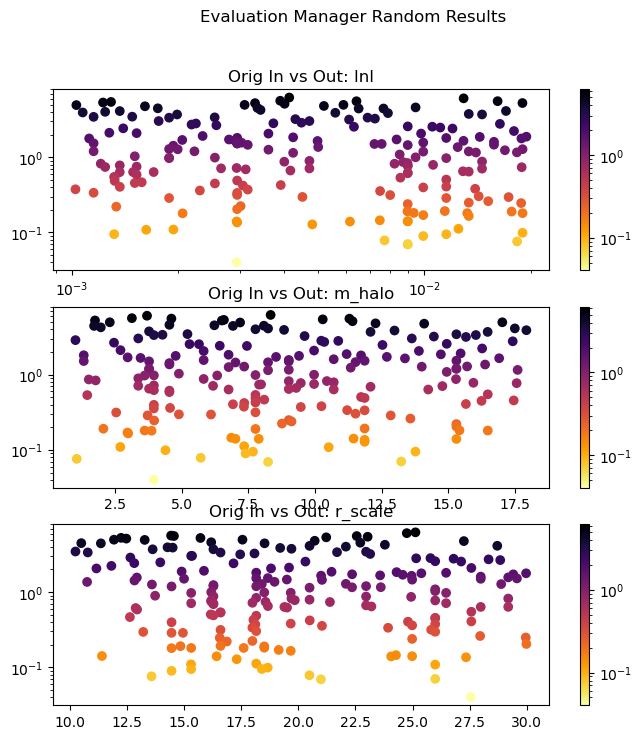

In [6]:
if buildEnv:

    import matplotlib.pyplot as plt
    
    # Create subplot for each dimension
    fig, axs = plt.subplots(3, figsize=(8, 8))

    # Set main title
    fig.suptitle("Evaluation Manager Random Results")

    # Histogram of inputs and outputs
    for i, dim_info in enumerate(space_manager.space_info):
        # inputs
        exec_manager.scatter_input(dim_index=i, space='original', external_ax=axs[i], title=f"Orig In vs Out: {dim_info['name']}", reverse_color=True, 
                                   output_log_scale=True)
    
    
    import Simulator.new_simulator as sim

    x, y = test_ga_manager.execution_manager.get_results(space='original')
    print( f"X: {x.shape} Y: {y.shape}" )

    # Get smallest y and x
    min_idx = np.argmin(y)
    min_x = x[min_idx]
    min_y = y[min_idx]

    print( f"Min Y: {min_y} Min X: {min_x}" )

    # Plot orbit of best
    npts = 4000
    best_hparam = { 'lnl': min_x[0], 'm_halo': min_x[1], 'r_scale': min_x[2] }
    best_orbit, _ = t1.simulate_orbit( orbit_data=best_hparam, save_dir=spam_loc )
    _, best_pts = sim.basic_run( t1.spam_ar, npts1=npts, npts2=npts, spam_setup_params=best_hparam )

    print( f"Best Orbit: {best_orbit.shape}" )
    print( f"Best Particles: {best_pts.shape}" )


<Figure size 640x480 with 0 Axes>

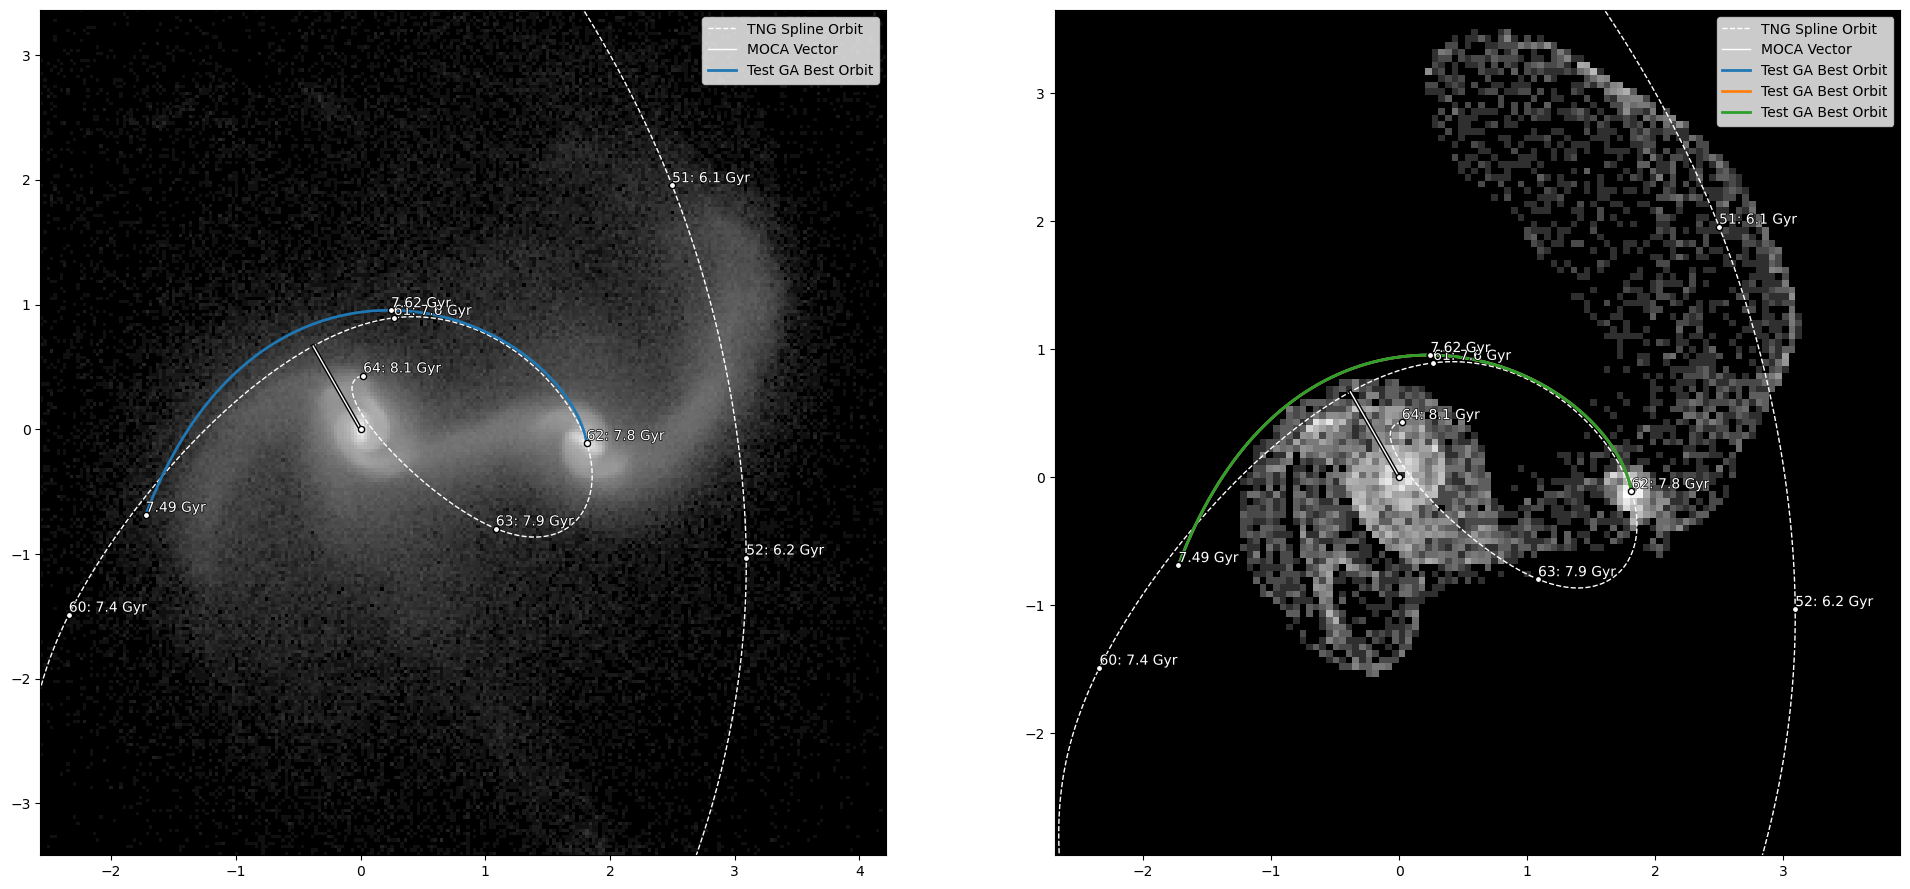

In [7]:

if buildEnv:

    plt.clf()
    # Create three side by side plots
    fig, axs = plt.subplots(1, 2, figsize=(24, 12))

    t1.graph_target(
        ax=axs[0],
        limits = None,
        add_spam_orbits= (best_orbit, 'Test GA Best Orbit'),
        # std_dev = 3,
    )

    t1.graph_target(
        ax=axs[1],
        overwrite_hist=best_pts,
        limits = None,
        add_spam_orbits= (best_orbit, 'Test GA Best Orbit'),
        # std_dev = 3,
    )


In [8]:

if buildEnv and False:

    # import IllustrisTNG.tng_functions as tf
    # import IllustrisTNG.convert_tng_to_spam as cts
    # reload( cts )
    reload( spam_tuner.cts )
    reload( spam_tuner )

    print( f"Best Orbit: {best_orbit.shape}" )
    print( f"Best Particles: {best_pts.shape}" )

    # Create three side by side plots
    fig, axs = plt.subplots(1, 2, figsize=(24, 12))


    t1.graph_target(
        ax=axs[0],
        limits = None,
        add_spam_orbits= (best_orbit, 'Test GA Best Orbit'),
        # std_dev = 3,
    )

    t1.graph_target(
        ax=axs[1],
        overwrite_hist=best_pts,
        limits = None,
        add_spam_orbits= (best_orbit, 'Test GA Best Orbit'),
        # std_dev = 3,
    )


In [16]:
class Tuner_Target_Setup:

    def __init__( self, target_id, ga_config=None ):

        self.logger = gu.configure_logger( logger_name='tuner_target_setup', log_level=logging.INFO )
        self.logger.info(f"Initializing Tuner Target Setup")

        self.target_id = target_id
        self.spam_loc = "/home/mbo2d/galStuff/data/misc_spam_orbits"
        self.target = spam_tuner.DEV_SPAM_TNG_Tuner( target_id, use_spline_type='hermite' )
        self.wf = self.target.gen_orbit_weights( boundary_value=0.1, scale_past=0.5 )

        self.spam_hyper_param = [
            {'name':'lnl', 'type': 'float', 'bounds': [1e-3, 2e-2], 'prior':'log-uniform', 'transform':'normalize',  },
            {'name':'m_halo', 'type': 'float', 'bounds': [1, 18], 'prior':'uniform', 'transform':'normalize', },
            {'name':'r_scale', 'type': 'float', 'bounds': [10, 30], 'prior':'uniform', 'transform':'normalize', },
        ]

        self.space_manager = opt_spt.Space_Manager( self.spam_hyper_param )
        self.logger.debug(f"Space Input: {self.space_manager.space_info}")

        self.exec_manager = opt_spt.Execution_Manager( self.space_manager,
                                                black_box_function=self.orbit_score_wrapper,
                                                normalize_output='reciprocal',
                                                func_logger='spam_tuner',
                                                )

        if ga_config is None:
            
            self.ga_config = {  
                "num_generations": 2,      # Number of generations to run the GA.
                "num_parents_mating": 20,  # Number of solutions to be selected as parents.
                "sol_per_pop": 64,        # Number of solutions per population.
                "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
                "keep_parents": 10,         # Number of top solutions to keep in the next generation.
                "parent_selection_type": "sus",   # Parent selection strategy 
                "crossover_type": "uniform", # Crossover strategy.        
                "mutation_probability": 0.5,      # Probability of mutating a gene.
                "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
                "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
                "random_seed": 0,       # Set random seed for reproducibility.
            }
        else:
            self.ga_config = ga_config
        

        self.ga_manager = PYGAD_Manager( self.ga_config,
                                        space_manager = self.space_manager,
                                        execution_manager = self.exec_manager,
                                        )

    def orbit_score_wrapper( self, x ):
        spam_hparam = { 'lnl': x[0], 'm_halo': x[1], 'r_scale': x[2] }
        orbit = self.target.simulate_orbit( orbit_data=spam_hparam, save_dir=self.spam_loc )
        orbit_error = self.target.weighted_avg_error_sq_over_by_time( orbit[0], self.wf )
        return orbit_error
    
    def run( self, ):
        self.ga_manager.gad.run()
    
    def get_best( self, npts=400, npts2=None ):
        x, y = self.exec_manager.get_results(space='original')
        # Get smallest y and x
        min_idx = np.argmin(y)
        min_x = x[min_idx]
        min_y = y[min_idx][0]

        best_hparam = { 'lnl': min_x[0], 'm_halo': min_x[1], 'r_scale': min_x[2] }
        best_orbit = self.target.simulate_orbit( orbit_data=best_hparam, save_dir=self.spam_loc )[0]


        if npts2 is None:
            npts2 = npts

        _, best_pts = sim.basic_run( self.target.spam_ar, npts1=npts, npts2=npts, spam_setup_params=best_hparam )

        best_dict = {
            'hparam': best_hparam,
            'orbit': best_orbit,
            'pts': best_pts,
            'score': min_y,
        }

        return best_dict

    def plot_best(self, npts=400):
        
        best_info = self.get_best(npts=npts)
        self.target.simulate_orbit( orbit_data=best_info['hparam'], save_dir=self.spam_loc, add_plot=True )

        print("Best Info:")
        print(f"\t- Hparam: {best_info['hparam']}")
        print(f"\t- Score: {best_info['score']}")
        print(f"\t- Orbit: {best_info['orbit'].shape}")
        print(f"\t- Particles: {best_info['pts'].shape}")
        
        fig, axs = plt.subplots(1, 2, figsize=(24, 12))

        fig.suptitle(f"Best Orbit: {best_info['score']:.3e}")

        self.target.graph_target(
            ax=axs[0],
            add_spam_orbits = (best_info['orbit'], "Best SPAM Orbit"),
        )

        self.target.graph_target(
            ax=axs[1],
            overwrite_hist=best_info['pts'],
            # add_spam_orbits = (best_info['orbit'], "Best SPAM Orbit"),
        )


if buildEnv:

    p2 = 75000000121160
    
    #####   GA MANAGER   ######
    test_ga_config = {
        "num_generations": 5,      # Number of generations to run the GA.
        "sol_per_pop": 32*2,        # Number of solutions per population.
        "num_parents_mating": int(32/2),  # Number of solutions to be selected as parents.
        "keep_parents": int(32/4),         # Number of top solutions to keep in the next generation.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
        "random_seed": 0,       # Set random seed for reproducibility.
    }

    # test_tuner = Tuner_Target_Setup( target_id = p2, ga_config=test_ga_config )
    test_tuner = Tuner_Target_Setup( target_id = p1, ga_config=test_ga_config )
    
    test_tuner.run()

    test_tuner.plot_best(npts=6000)    


[2025-03-17 15:19:36,393 - INFO - 3326464394.__init__]: Initializing Tuner Target Setup
[2025-03-17 15:19:39,556 - INFO - optimization_support.Space_Manager.__init__]: Initializing Space Manager
[2025-03-17 15:19:39,556 - INFO - optimization_support.__init__]: Initializing Space Manager
[2025-03-17 15:19:39,563 - INFO - optimization_support.Space_Manager.__init__]: Space Manager Initialized
[2025-03-17 15:19:39,563 - INFO - optimization_support.__init__]: Space Manager Initialized
[2025-03-17 15:19:39,564 - INFO - optimization_support.execution_manager.__init__]: Initializing Execution Manager
[2025-03-17 15:19:39,564 - INFO - optimization_support.__init__]: Initializing Execution Manager
[2025-03-17 15:19:39,810 - INFO - parallel_queue_manager.Queue_Manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).
[2025-03-17 15:19:39,810 - INFO - parallel_queue_manager._set_local_mode]: Local Manager initialized with 32 workers using local mul

KeyboardInterrupt: 

[2025-03-17 15:20:05,927 - INFO - 3326464394.__init__]: Initializing Tuner Target Setup
[2025-03-17 15:20:06,696 - INFO - optimization_support.execution_manager.__del__]: Execution Manager Terminated
[2025-03-17 15:20:06,696 - INFO - optimization_support.__del__]: Execution Manager Terminated
[2025-03-17 15:20:06,699 - INFO - parallel_queue_manager.Queue_Manager.__del__]: Queue Manager Deleted
[2025-03-17 15:20:06,699 - INFO - parallel_queue_manager.__del__]: Queue Manager Deleted
[2025-03-17 15:20:10,674 - INFO - optimization_support.Space_Manager.__init__]: Initializing Space Manager
[2025-03-17 15:20:10,674 - INFO - optimization_support.__init__]: Initializing Space Manager
[2025-03-17 15:20:10,680 - INFO - optimization_support.Space_Manager.__init__]: Space Manager Initialized
[2025-03-17 15:20:10,680 - INFO - optimization_support.__init__]: Space Manager Initialized
[2025-03-17 15:20:10,681 - INFO - optimization_support.execution_manager.__init__]: Initializing Execution Manager
[

Best Info:
	- Hparam: {'lnl': 0.00897978509495963, 'm_halo': 1.1337229105465498, 'r_scale': 12.839541403187308}
	- Score: 0.013274395872691165
	- Orbit: (1750, 7)
	- Particles: (12001, 6)


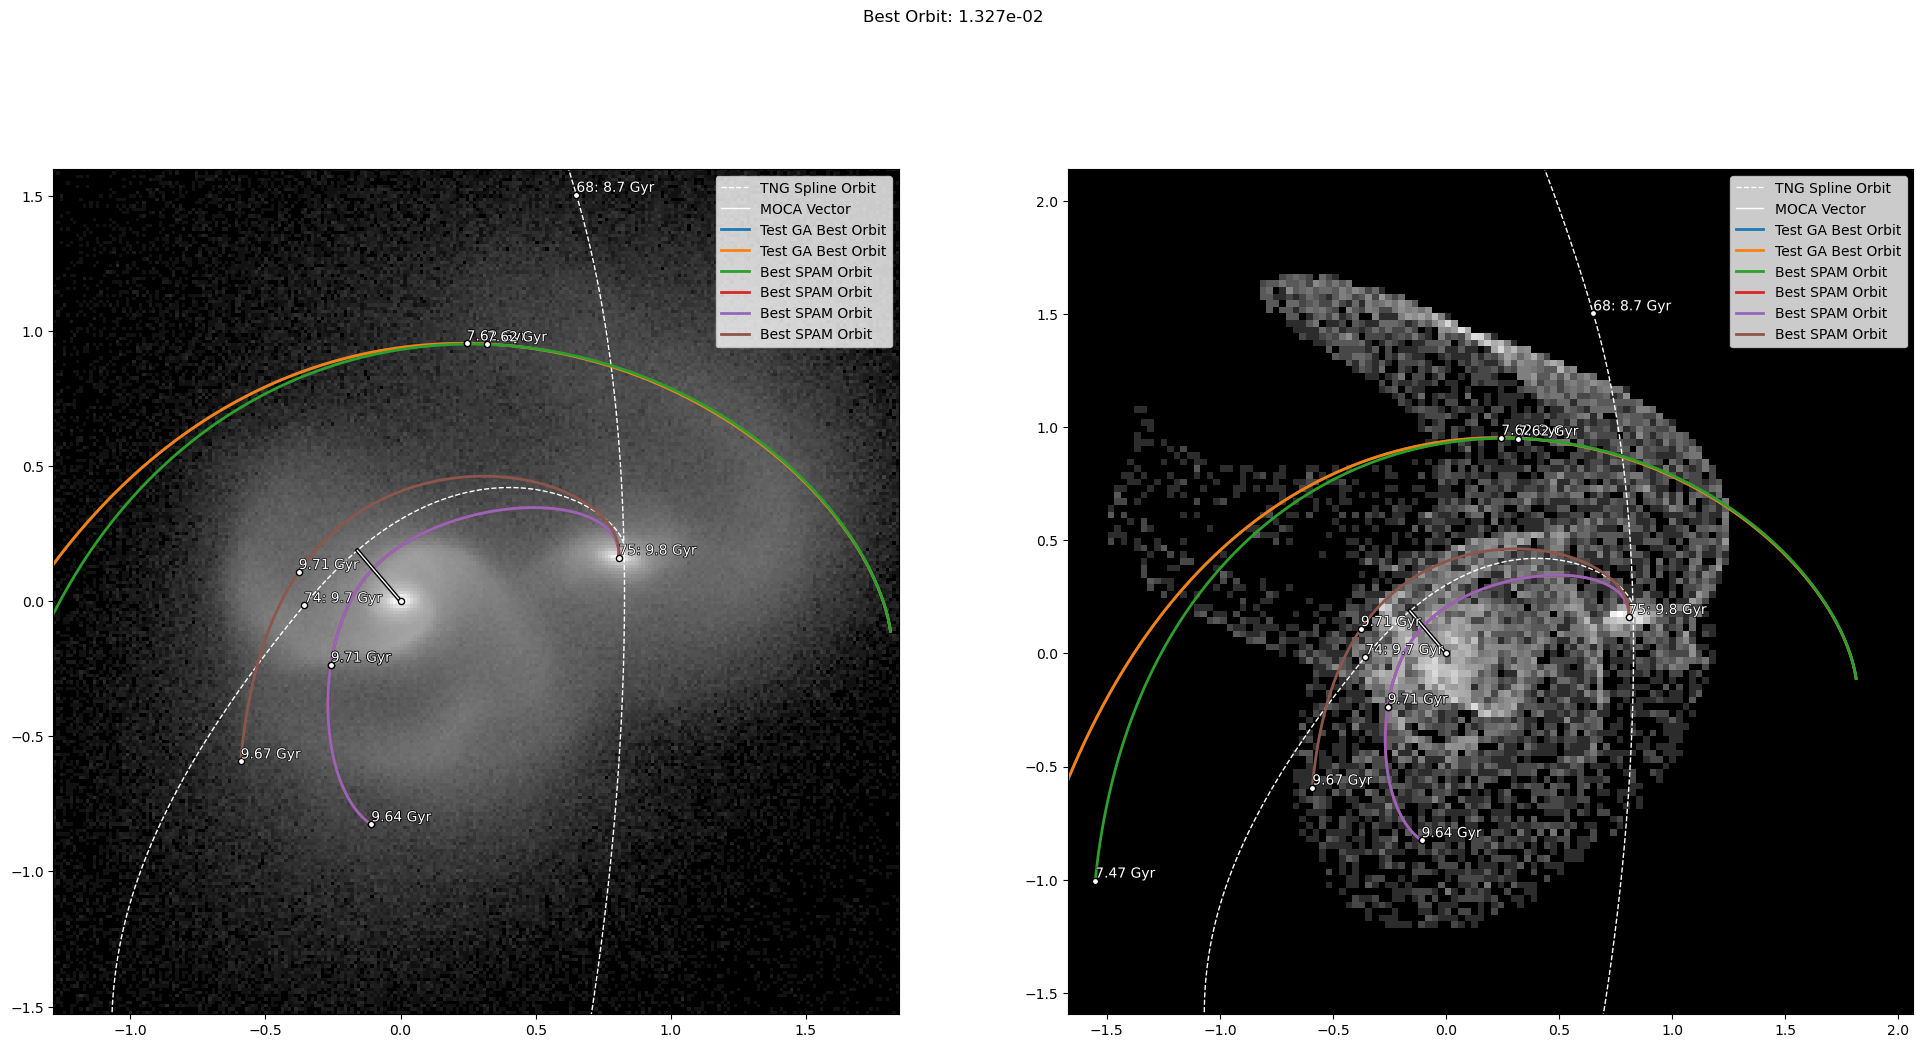

In [17]:

if buildEnv:

    p2 = 75000000121160
    
    #####   GA MANAGER   ######
    test_ga_config = {
        "num_generations": 5,      # Number of generations to run the GA.
        "sol_per_pop": 32*2,        # Number of solutions per population.
        "num_parents_mating": int(32/2),  # Number of solutions to be selected as parents.
        "keep_parents": int(32/4),         # Number of top solutions to keep in the next generation.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
        "random_seed": 0,       # Set random seed for reproducibility.
    }

    test_tuner = Tuner_Target_Setup( target_id = p2, ga_config=test_ga_config )
    # test_tuner = Tuner_Target_Setup( target_id = p1, ga_config=test_ga_config )
    
    test_tuner.run()

    test_tuner.plot_best(npts=6000)    


In [ ]:
if buildEnv:
    p3 = 51000000255938

    test_tuner = Tuner_Target_Setup( target_id = p3, ga_config=test_ga_config )
    
    test_tuner.run()

    test_tuner.plot_best(npts=3000)    

    

[2025-03-17 15:09:14,558 - INFO - 515341975.__init__]: Initializing Tuner Target Setup
[2025-03-17 15:09:14,560 - INFO - convert_tng_to_spam.__init__]: Initializing TNG Target Class...
[2025-03-17 15:09:15,758 - INFO - optimization_support.execution_manager.__del__]: Execution Manager Terminated
[2025-03-17 15:09:15,758 - INFO - optimization_support.__del__]: Execution Manager Terminated
[2025-03-17 15:09:15,942 - INFO - parallel_queue_manager.Queue_Manager.__del__]: Queue Manager Deleted
[2025-03-17 15:09:15,942 - INFO - parallel_queue_manager.__del__]: Queue Manager Deleted


IndexError: index -1 is out of bounds for axis 0 with size 0

In [11]:


def _on_parents(self, ga_instance, parents):
        """Custom on_parents function for the GA."""
        self.logger.info("On Parents")
        self.logger.debug(f"Parents: {type(parents)}")
        # self.logger.debug(f"Parents: \n{parents[:2]}\n...\n{parents[-2:]}")
        self.logger.info("On Parents Complete")
    # end of _on_parents

def custom_run(self, generations=None):
        """Custom run method for the GA."""
        self.logger.info("Custom Run")
        
        if generations is None:
            generations = self.ga_config['num_generations']
        
        self.logger.info(f"Running GA for {generations} generations")
        self._custom_fitness()

        self.gad.on_parents( self.gad, self.gad.last_generation_parents )
    

if buildEnv:

    ga_config['sol_per_pop'] = 10

    # Create new GA
    my_ga = PYGAD_Manager( ga_config, input_space=test_space, black_box_function=good_function, logger=debug_logger )

    # my_ga.custom_run()
    my_ga.gad.run()
        

NameError: name 'debug_logger' is not defined

# Matt's MISC Notes:

1) Considering a live heat scatter plot
    - Use PCA to lower dimensions to 2.  (maybe 3)
    - Have code generate a frame to add to gif every generation.
    - increase speed of plot as frames increase

2) Use timestamps in a folder to create unique folders/files over time.

3) Have a table of the input dimensions
    - color code convergience versus sensitivety.
    - Color code degeneracies with other parameters??
    - Find color-blind approved color sprectrum. 


In [ ]:

    def _on_start(self, ga_instance):
        """Called once before the genetic algorithm starts."""
        self.logger.info("On Start")
        pass

    def _on_fitness(self, ga_instance, fitness_values):
        """Called after calculating the fitness values of all solutions."""
        self.logger.info("GA: On Fitness")
        pass

    def _on_parents(self, ga_instance, parents):
        """Called after selecting parents for mating."""
        self.logger.info("GA: On Parents")
        pass

    def _on_crossover(self, ga_instance, offspring):
        """Called each time the crossover operation is applied."""
        self.logger.info("GA: On Crossover")
        pass

    def _on_mutation(self, ga_instance, mutated_offspring):
        """Called each time the mutation operation is applied."""
        self.logger.info("GA: On Mutation")
        pass

    def _on_generation(self, ga_instance):
        """ Callback for each generation """
        self.logger.info(f"Generation: {ga_instance.generations_completed} Best Fitness: {ga_instance.best_solution()[1]}") 
    
    def _on_stop(self, ga_instance, last_gen_fitness):
        """Called once before the algorithm stops or after the last generation."""
        self.logger.info("GA: On Stop")
        pass

    def _custom_crossover_mask(self, parents, offspring_size):
        """ TODO custom crossover function for scattered crossover """
        pass


In [ ]:
import numpy as np

def simulated_annealing_mutation(ga_instance):
    # Calculate progress through generations
    progress = ga_instance.generations_completed / ga_instance.num_generations

    # Exponential decay for temperature (annealing schedule)
    initial_temp = 1.0
    final_temp = 0.01
    temperature = initial_temp * (final_temp / initial_temp) ** progress

    # Adjust mutation range based on temperature
    mutation_range = temperature * 0.3  # Starting range scaled by temperature
    ga_instance.random_mutation_min_val = -mutation_range
    ga_instance.random_mutation_max_val = mutation_range

    # Adjust mutation probability (optional)
    ga_instance.mutation_probability = temperature * 0.5 + 0.05  # Keeps a baseline probability

    # (Optional) Print progress for monitoring
    print(f"Generation {ga_instance.generations_completed} | Temp: {temperature:.4f} | Mutation Range: ±{mutation_range:.4f} | Mutation Prob: {ga_instance.mutation_probability:.4f}")
